### Hierarchical clustering
First step by step, later fully automated

In [1]:
import pandas as pd # For viewing
import numpy as np  # For data generation

np.random.seed(123)

variables = ['X', 'Y', 'Z'] # features
labels = ['ID_0', 'ID_1', 'ID_2', 'ID_3', 'ID_4'] # sample names

X = np.random.random_sample([5, 3])*10
df = pd.DataFrame(X, columns=variables, index=labels)
df

,X,Y,Z
ID_0,6.964692,2.861393,2.268515
ID_1,5.513148,7.194690,4.231065
ID_2,9.807642,6.848297,4.809319
ID_3,3.921175,3.431780,7.290497
ID_4,4.385722,0.596779,3.980443


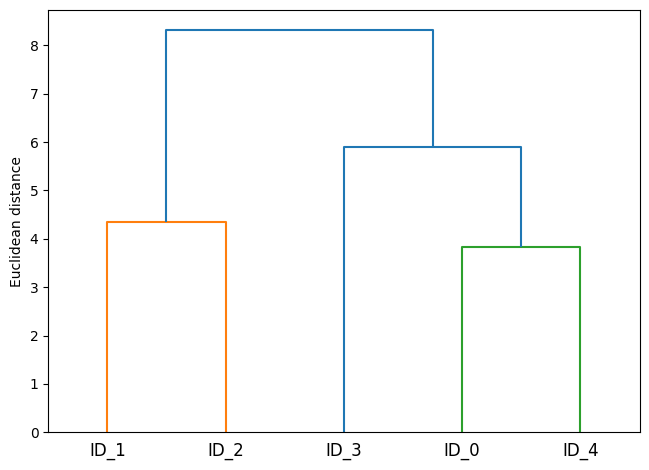

In [3]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import linkage

row_clusters = linkage(df.values, method='complete', metric='euclidean')

# Make dendrogram black (part 1/2):
# from scipy.cluster.hierarchy import set_link_color_palette
# set_link_color_palette(['black']) # Reset with None

row_dendr = dendrogram(row_clusters,
                       labels=labels,
                       # Make dendrogram black (part 2/2):
                       # color_threshold=np.inf
                       )
plt.tight_layout()
plt.ylabel('Euclidean distance')
plt.show()

Back to presentation

### Heat maps
(The manual way)

<ipython-input-4-381dc2ec4372>:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axm.set_xticklabels([''] + list(df_rowclust.columns)) # Warning from matplotlib >3.2.2
<ipython-input-4-381dc2ec4372>:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axm.set_yticklabels([''] + list(df_rowclust.index))


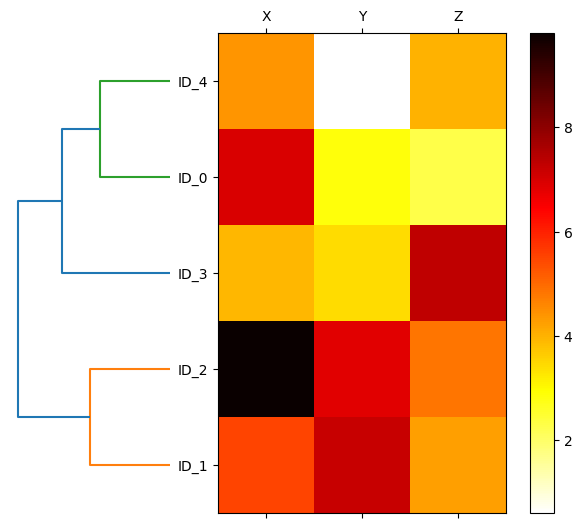

In [4]:
# Plot row dendrogram
fig = plt.figure(figsize=(8, 8), facecolor='white')
axd = fig.add_axes([0.09, 0.1, 0.2, 0.6])
row_dendr = dendrogram(row_clusters, orientation='left')

# Reorder data with respect to clustering
df_rowclust = df.iloc[row_dendr['leaves'][::-1]]

# Remove ticks
axd.set_xticks([])
axd.set_yticks([])

# Remove axes spines from dendrogram
for i in axd.spines.values():
    i.set_visible(False)

# Plot heatmap
axm = fig.add_axes([0.23, 0.1, 0.6, 0.6])  # x-pos, y-pos, width, height
cax = axm.matshow(df_rowclust, interpolation='nearest', cmap='hot_r')
fig.colorbar(cax)
axm.set_xticklabels([''] + list(df_rowclust.columns)) # Warning from matplotlib >3.2.2
axm.set_yticklabels([''] + list(df_rowclust.index))

plt.show()

#### Two-way clustering with heatmap

In [5]:
column_clusters = linkage(df.values.T, method='complete', metric='euclidean')
pd.DataFrame(column_clusters,
             columns=['column label 1', 'column label 2',
                      'distance', 'no. of items in clust.'],
             index=['cluster %d' % (i + 1)
                    for i in range(column_clusters.shape[0])])

,column label 1,column label 2,distance,no. of items in clust.
cluster 1,1.0,2.0,6.295307,2.0
cluster 2,0.0,3.0,7.758713,3.0


<ipython-input-6-f0aa98ac61ad>:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axm.set_xticklabels([''] + list(df_rowclust.columns)) # Warning from matplotlib >3.2.2
<ipython-input-6-f0aa98ac61ad>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axm.set_yticklabels([''] + list(df_rowclust.index))


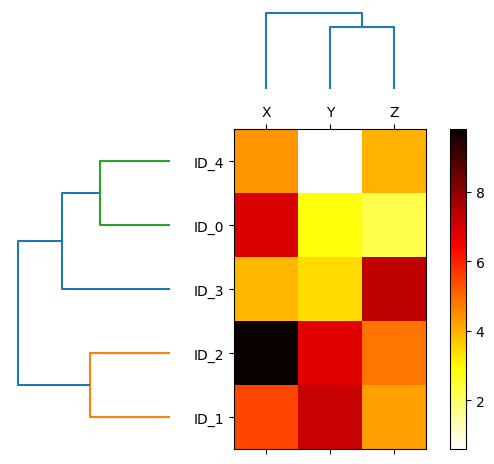

In [6]:
# Plot row dendrogram
fig = plt.figure(figsize=(8, 8), facecolor='white')
axd1 = fig.add_axes([0.09, 0.1, 0.2, 0.4]) # Values found more or less by trial and error
row_dendr = dendrogram(row_clusters, orientation='left')
axd2 = fig.add_axes([0.37, 0.55, 0.24, 0.1])
column_dendr = dendrogram(column_clusters)

# Reorder data with respect to clustering
df_rowclust = df.iloc[row_dendr['leaves'][::-1]]
df_rowclust = df_rowclust.iloc[:,column_dendr['leaves']]

# Remove ticks
axd1.set_xticks([])
axd1.set_yticks([])
axd2.set_xticks([])
axd2.set_yticks([])

# Remove axes spines from dendrogram
for i in axd1.spines.values():
    i.set_visible(False)
for i in axd2.spines.values():
    i.set_visible(False)

# Plot heatmap
axm = fig.add_axes([0.13, 0.1, 0.6, 0.4])  # x-pos, y-pos, width, height
cax = axm.matshow(df_rowclust, interpolation='nearest', cmap='hot_r')
fig.colorbar(cax)
axm.set_xticklabels([''] + list(df_rowclust.columns)) # Warning from matplotlib >3.2.2
axm.set_yticklabels([''] + list(df_rowclust.index))

plt.show()

### Or do something similar in one line using seaborn

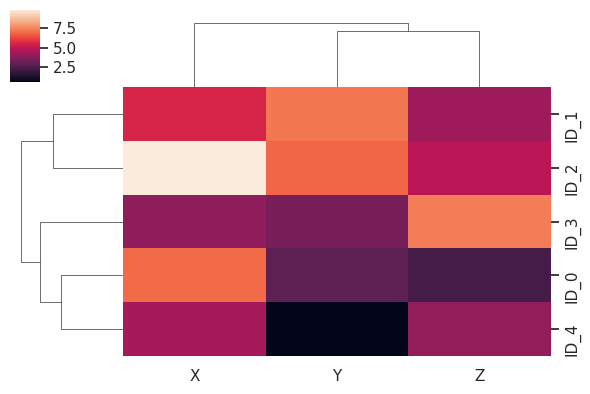

In [7]:
import seaborn as sns; sns.set(color_codes=True)

g = sns.clustermap(df, figsize=(6, 4))

#### scikit-learn style

In [9]:
from sklearn.cluster import AgglomerativeClustering

ac = AgglomerativeClustering(n_clusters=3,
                             metric='euclidean',
                             linkage='complete')

labels = ac.fit_predict(X)
print('Cluster labels:', labels)


Cluster labels: [1 0 0 2 1]


In [12]:
ac = AgglomerativeClustering(n_clusters=2,
                             metric='euclidean',
                             linkage='complete')
labels = ac.fit_predict(X)
print('Cluster labels: %s' % labels)

Cluster labels: [0 1 1 0 0]


Back to presentation

### DBSCAN

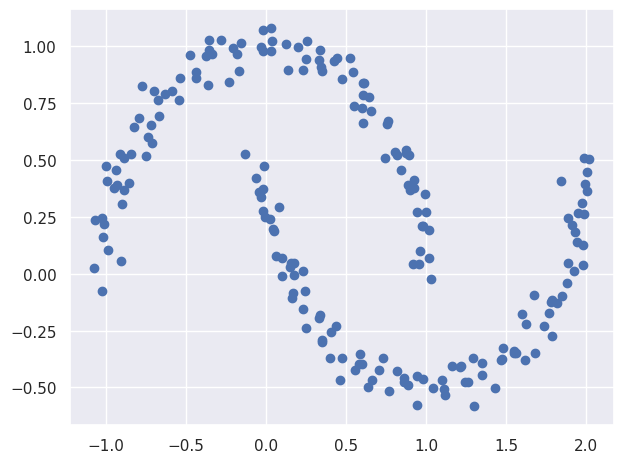

In [13]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=200, noise=0.05, random_state=0)
plt.scatter(X[:, 0], X[:, 1])
plt.tight_layout()
plt.show()

#### K-means and hierarchical clustering on moons

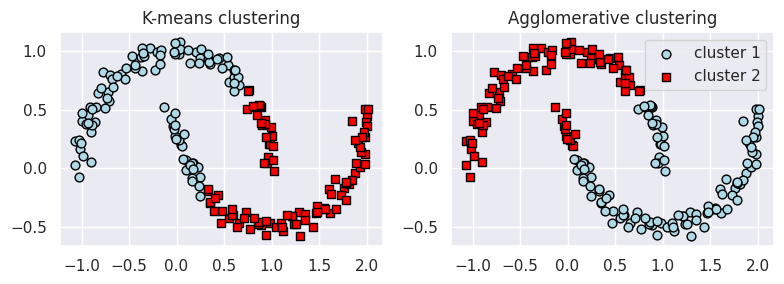

In [15]:
from sklearn.cluster import KMeans
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

km = KMeans(n_clusters=2, random_state=0)
y_km = km.fit_predict(X)
ax1.scatter(X[y_km == 0, 0], X[y_km == 0, 1],
            edgecolor='black',
            c='lightblue', marker='o', s=40, label='cluster 1')
ax1.scatter(X[y_km == 1, 0], X[y_km == 1, 1],
            edgecolor='black',
            c='red', marker='s', s=40, label='cluster 2')
ax1.set_title('K-means clustering')

ac = AgglomerativeClustering(n_clusters=2,
                             metric='euclidean',
                             linkage='complete')
y_ac = ac.fit_predict(X)
ax2.scatter(X[y_ac == 0, 0], X[y_ac == 0, 1], c='lightblue',
            edgecolor='black',
            marker='o', s=40, label='cluster 1')
ax2.scatter(X[y_ac == 1, 0], X[y_ac == 1, 1], c='red',
            edgecolor='black',
            marker='s', s=40, label='cluster 2')
ax2.set_title('Agglomerative clustering')

plt.legend()
plt.tight_layout()
plt.show()

### DBSCAN

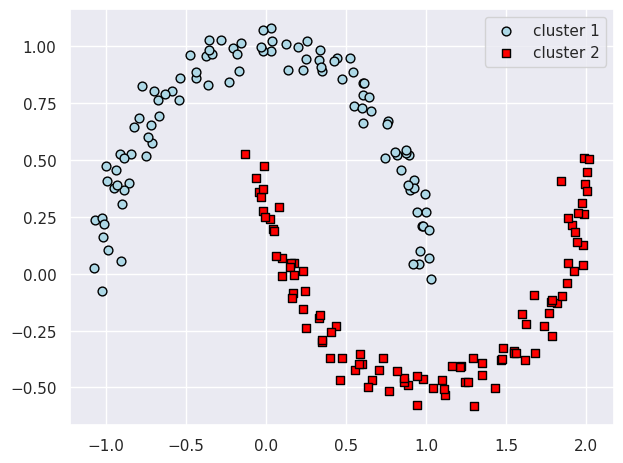

In [16]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.2, min_samples=5, metric='euclidean')
y_db = db.fit_predict(X)
plt.scatter(X[y_db == 0, 0], X[y_db == 0, 1],
            c='lightblue', marker='o', s=40,
            edgecolor='black',
            label='cluster 1')
plt.scatter(X[y_db == 1, 0], X[y_db == 1, 1],
            c='red', marker='s', s=40,
            edgecolor='black',
            label='cluster 2')
plt.legend()
plt.tight_layout()
plt.show()

<ipython-input-17-0e4a214fe050>:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  edgecolor='black', cmap=plt.cm.get_cmap('RdBu')) # Red-blue colormap


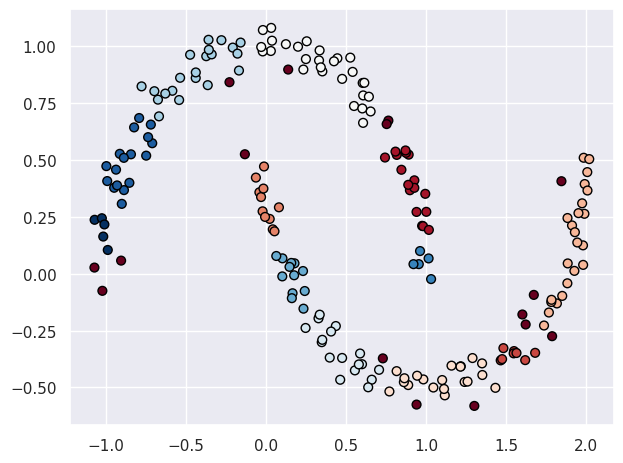

Number of clusters: 11


In [17]:
# Sensitivity to parameter settings:
db = DBSCAN(eps=0.1, min_samples=4, metric='euclidean') # Different eps and min_samples
y_db = db.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1],
            c=y_db, marker='o', s=40,
            edgecolor='black', cmap=plt.cm.get_cmap('RdBu')) # Red-blue colormap
plt.tight_layout()
plt.show()
print("Number of clusters: %s" % np.max(y_db))

Back to presentation